# Homework Heuristic Search

First let's import some modules

In [111]:
from domain.agent import Agent
from maze_generators import randomized, backtracking
from heuristics import manhattan, euclidean
import time
import matplotlib.pyplot as plt
from screen import animation
from IPython.display import Video
import os
import tracemalloc
import cProfile

create some constants and functions used in our notebook

In [100]:
HEIGHT = 10
WIDTH = 10
TIMESTAMP_STRING = "Elapsed time: %s seconds"
PATH_LENGTH_STRING = "Path length: %s cells"
MEMORY_BLOCKS_ALLOCATED_STRING = "Current memory usage is %f MB; Peak was %f MB"
MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME = "MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME"
EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME = "EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME"
MANHATTAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME = "MANHATTAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME"
EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME = "EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME"
DFS_VIDEO_FILE_NAME = "DFS_VIDEO_FILE_NAME"
VIDEO_EXTENSION = ".mp4"
VIDEO_FILE_NAMES = {
    MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME: "manhattan_distance_heuristic_best_first" + VIDEO_EXTENSION,
    EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME: "euclidean_distance_heuristic_best_first" + VIDEO_EXTENSION,
    MANHATTAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME: "manhattan_distance_heuristic_a_star" + VIDEO_EXTENSION,
    EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME: "euclidean_distance_heuristic_a_star" + VIDEO_EXTENSION,
    DFS_VIDEO_FILE_NAME: "dfs" + VIDEO_EXTENSION,
}

def compute_allocated_memory_blocks_in_MB(traced_memory_stats):
    current_memory_usage_in_MB = traced_memory_stats[0] / 10**6
    peak_memory_usage_in_MB = traced_memory_stats[1] / 10**6
    return current_memory_usage_in_MB, peak_memory_usage_in_MB

and remove some old files

In [101]:
for video_name in VIDEO_FILE_NAMES:
    video = VIDEO_FILE_NAMES[video_name]
    if os.path.exists(video):
      os.remove(video)
      print(f"File '{video}' deleted successfully.")
    else:
      print(f"File '{video}' does not exist.")

File 'manhattan_distance_heuristic_best_first.mp4' deleted successfully.
File 'euclidean_distance_heuristic_best_first.mp4' deleted successfully.
File 'manhattan_distance_heuristic_a_star.mp4' deleted successfully.
File 'euclidean_distance_heuristic_a_star.mp4' deleted successfully.
File 'dfs.mp4' deleted successfully.


then let's generate a maze with random obstacles

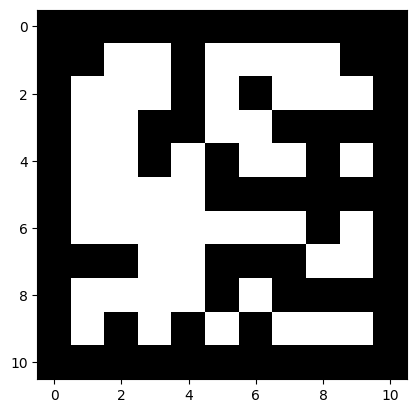

In [102]:
maze = randomized.create_maze(HEIGHT, WIDTH)
plt.imshow(maze.maze, cmap='gray')
plt.show()

and put an agent inside it.

In [103]:
agent = Agent(maze)

Now that everything is set up we can start solving this maze with different algorithms.  
In every maze solution that will follow, start position is **(0,0)** and goal is **(n,n)**

## Best First Algorithm

The first algorithm to test will be the best first algorithm

### Manhattan Distance Heuristic

Let's test the best first algorithm with Manhattan distance heuristic on the previously generated maze

Elapsed time: 0.003001689910888672 seconds
Path length: 79 cells


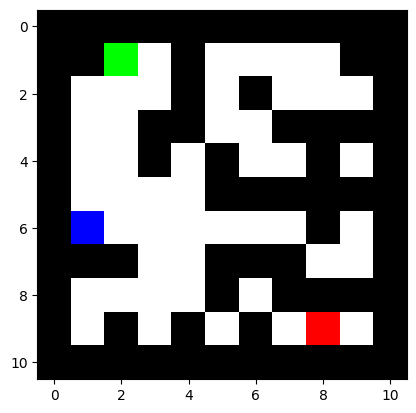

In [104]:
manhattan_distance_heuristic_best_first_start_time = time.time()
manhattan_distance_heuristic_best_first_path = agent.best_first(manhattan.manhattan_distance_heuristic)
manhattan_distance_heuristic_best_first_end_time = time.time() - manhattan_distance_heuristic_best_first_start_time
print(TIMESTAMP_STRING % manhattan_distance_heuristic_best_first_end_time)
print(PATH_LENGTH_STRING % len(manhattan_distance_heuristic_best_first_path))
animation.animate(maze, manhattan_distance_heuristic_best_first_path, VIDEO_FILE_NAMES[MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME])
Video(VIDEO_FILE_NAMES[MANHATTAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME])

### Euclidean Distance Heuristic

Let's test the best first algorithm with Euclidean distance heuristic on the previously generated maze

Elapsed time: 0.002002716064453125 seconds
Path length: 106 cells


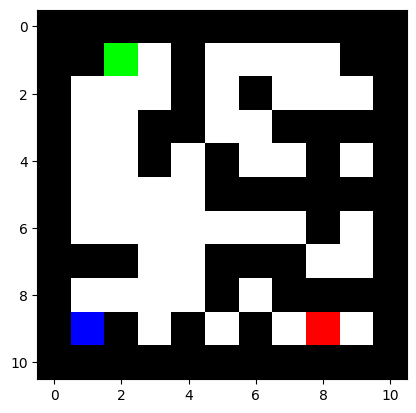

In [105]:
euclidean_distance_heuristic_best_first_start_time = time.time()
euclidean_distance_heuristic_best_first_path = agent.best_first(euclidean.euclidean_distance_heuristic)
euclidean_distance_heuristic_best_first_end_time = time.time() - euclidean_distance_heuristic_best_first_start_time
print(TIMESTAMP_STRING % euclidean_distance_heuristic_best_first_end_time)
print(PATH_LENGTH_STRING % len(euclidean_distance_heuristic_best_first_path))
animation.animate(maze, euclidean_distance_heuristic_best_first_path, VIDEO_FILE_NAMES[EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME])
Video(VIDEO_FILE_NAMES[EUCLIDEAN_DISTANCE_HEURISTIC_BEST_FIRST_VIDEO_FILE_NAME])

## A* Algorithm

Having seen the Best First algorithm we now focus on the A* algorithm in both heuristics

### Manhattan Distance Heuristic

Let's test the A* algorithm with the Manhattan distance heuristic

Elapsed time: 0.002001523971557617 seconds
Path length: 64 cells


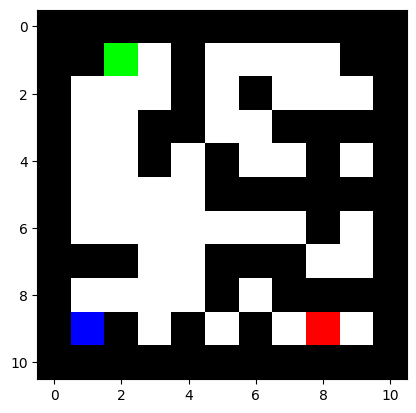

In [106]:
manhattan_distance_heuristic_a_star_start_time = time.time()
manhattan_distance_heuristic_a_star_path = agent.a_star(manhattan.manhattan_distance_heuristic)
manhattan_distance_heuristic_a_star_end_time = time.time() - manhattan_distance_heuristic_a_star_start_time
print(TIMESTAMP_STRING % manhattan_distance_heuristic_a_star_end_time)
print(PATH_LENGTH_STRING % len(manhattan_distance_heuristic_a_star_path))
animation.animate(maze, manhattan_distance_heuristic_a_star_path, VIDEO_FILE_NAMES[MANHATTAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME])
Video(VIDEO_FILE_NAMES[MANHATTAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME])

### Euclidean Distance Heuristic

Let's test the A* algorithm with the Euclidean distance heuristic

Elapsed time: 0.004002094268798828 seconds
Path length: 78 cells


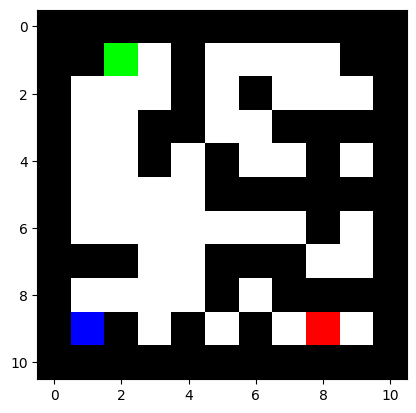

In [107]:
euclidean_distance_heuristic_a_star_start_time = time.time()
euclidean_distance_heuristic_a_star_path = agent.a_star(euclidean.euclidean_distance_heuristic)
euclidean_distance_heuristic_a_star_end_time = time.time() - euclidean_distance_heuristic_a_star_start_time
print(TIMESTAMP_STRING % euclidean_distance_heuristic_a_star_end_time)
print(PATH_LENGTH_STRING % len(euclidean_distance_heuristic_a_star_path))
animation.animate(maze, euclidean_distance_heuristic_a_star_path, VIDEO_FILE_NAMES[EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME])
Video(VIDEO_FILE_NAMES[EUCLIDEAN_DISTANCE_HEURISTIC_A_STAR_VIDEO_FILE_NAME])

## DFS Algorithm

Another algorithm worth of mentioning is the Depth First Search (or DFS) algorithm. Let's test how it performs as a maze runner.

Path length: 67 cells
         15286 function calls (12822 primitive calls) in 0.005 seconds

   Ordered by: standard name

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.005    0.005 <string>:1(<module>)
        1    0.000    0.000    0.005    0.005 agent.py:184(dfs)
        1    0.000    0.000    0.004    0.004 agent.py:268(reverse_path)
     29/1    0.000    0.000    0.004    0.004 agent.py:282(online_path)
       40    0.000    0.000    0.000    0.000 agent.py:306(check_if_two_cells_are_neighbours)
        2    0.000    0.000    0.000    0.000 agent.py:315(compute_path_to_turning_point)
  2464/28    0.002    0.000    0.004    0.000 copy.py:128(deepcopy)
     1624    0.000    0.000    0.000    0.000 copy.py:182(_deepcopy_atomic)
      812    0.001    0.000    0.003    0.000 copy.py:209(_deepcopy_tuple)
      812    0.000    0.000    0.002    0.000 copy.py:210(<listcomp>)
       28    0.000    0.000    0.004    0.000 copy.py:2

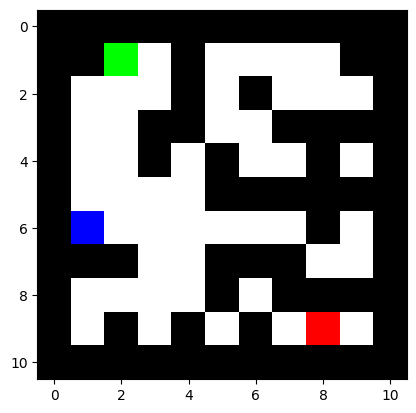

In [110]:
dfs_path = agent.dfs()
print(PATH_LENGTH_STRING % len(dfs_path))
cProfile.run('agent.dfs()')
animation.animate(maze, dfs_path, VIDEO_FILE_NAMES[DFS_VIDEO_FILE_NAME])
Video(VIDEO_FILE_NAMES[DFS_VIDEO_FILE_NAME])

Note that as this algorithm does not use an heuristic, it is much slower to find a path than the other two!

## Backtracking Generated Maze

Until now we have seen algorithms working a maze generated with random obstacles, but what about a true maze with paths generated by a backtracking algorithm like the following one?

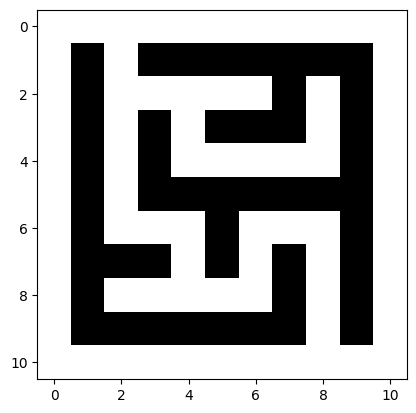

In [115]:
backtracking_generated_maze = backtracking.create_maze(HEIGHT, WIDTH)
plt.imshow(backtracking_generated_maze.maze, cmap='gray')
plt.show()

## Comparisons

Having seen three different algorithms for solving the generated 10x10 maze, we can tell that DFS and Best-first are not optimal because, while DFS often finds a solution quickly, it is not necessarily the shortest one, meanwhile the solution provided by the Best-first algorithm strongly depends on the quality of the heuristic function. A* on the other hand is optimal if the heurstic function is consistent (monotonically increasing).

Talking about time complexity, DFS has O(|V| + |E|) in the worst case, where |V| is the number of vertices and |E| is the number of edges, while Best-first varies based on the heuristic and the problem and A* is exponential in the worst case but oftern performs much ebtter inm pratice with a good heuristic.

Lastly, space complexity is also a factor to consider when comparing algorithms. On one hand we know that DFS has a space complexity of O(|V|) in the worst case, while on the other Best-first can vary widely, depending on the implementation and the heuristic function and A* is exponential in the worst case.

In conclusion we could say that:
- the DFS algorithm is good for finding a solution quickly, but may not be optimal, so it can be used when the search space is finite and the depth of the solution is known to be relatively small;
- Best-first can be faster than DFS, but less reliable, meaning that it could be used when a good heuristic function is available;
- A* is often the best choice for finding optimal solutions efficiently, so it can be used when a good heuristic function is available and the search space is large.